<a href="https://colab.research.google.com/github/jiyeonlee-2930/HandsOn-LLM/blob/main/12%EC%A3%BC%EC%B0%A8_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 사전 학습된 LLM을 불러와서, 사용자가 입력한 문장을 토큰으로 변환하고 새로운 텍스트로 생성하는 과정


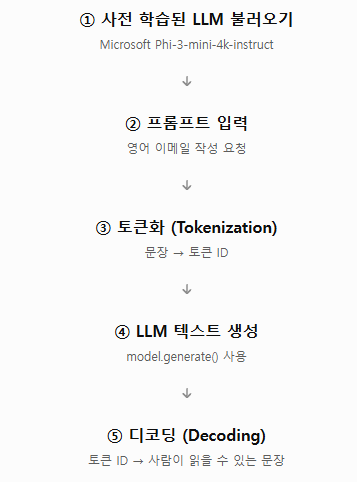

# Transformer의 디코더 구조를 사용하는 LLM이 텍스트를 생성하는 과정

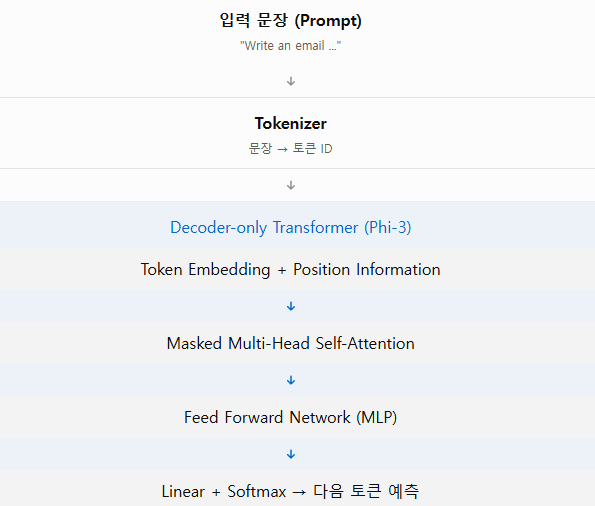

In [ ]:
# 깃허브에서 위젯 상태 오류를 피하기 위해 진행 표시줄을 나타내지 않도록 설정합니다.
from transformers.utils import logging

logging.disable_progress_bar()

In [ ]:
##LLM로드하기
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# GPU 사용 가능 여부에 따라 디바이스를 설정합니다.
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# LLM을 불러와 텍스트 생성(추론, Inference) 과정
model = AutoModelForCausalLM.from_pretrained(
    "microsoft/Phi-3-mini-4k-instruct", ## Decoder-only Transformer
    device_map=device,
    torch_dtype="auto"
)
tokenizer = AutoTokenizer.from_pretrained("microsoft/Phi-3-mini-4k-instruct")

In [ ]:
##Phi-3 내부 구조
print(model)

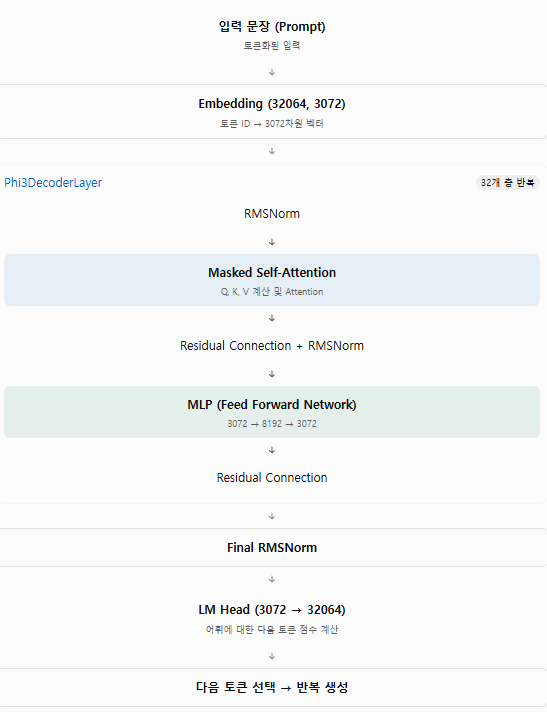

# 훈프롬프트 입력과 토큰화

In [ ]:
prompt = "Write an email apologizing to Sarah for the tragic gardening mishap. Explain how it happened.<|assistant|"

# 입력 프롬프트를 토큰으로 나누고, 앞서 설정한 디바이스(cpu 또는 cuda)를 사용.텐서 형태로 변환
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)

# 텍스트를 생성합니다.
generation_output = model.generate(
  input_ids=input_ids,
  max_new_tokens=20
)



In [ ]:
## 토큰 아이디 배열
print(input_ids)

In [ ]:
for id in input_ids[0]:
   print(tokenizer.decode(id))

In [ ]:
generation_output


In [ ]:
# 생성된 토큰을 문장으로 변환하여 첫번째 입력에 대한 생성 결과 출력
print(tokenizer.decode(generation_output[0]))

In [ ]:
## 세롭게 생성된 문장만 출력
new_tokens = generation_output[0][input_ids.shape[1]:]

print(tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
))

In [ ]:
## 개선된 코드 ; 채팅 템플릿을 적용하여 프롬프트를 개선하고, 생성된 답변이 다양하도록 수정
# 1. 사용자 질문
prompt = "Write an email apologizing to Sarah for the gardening mishap."

# 2. Phi-3 채팅 템플릿 적용
messages = [
    {
        "role": "system",
        "content": "Explain concepts to a 10-year-old child."
        },
    {
        "role": "user", "content": prompt
        }
]

# 템플릿을 사용하여 안전하게 리스트 형태로 출력값을 받아옵니다.
raw_ids = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    return_tensors=None
)

# raw_ids가 dict 형태(BatchEncoding 등)일 경우 input_ids 키를 추출하고, 그렇지 않다면 그대로 사용합니다.
if isinstance(raw_ids, dict) or hasattr(raw_ids, "data"):
    if "input_ids" in raw_ids:
        raw_ids = raw_ids["input_ids"]

import torch
# 얻어온 토큰 ID 리스트를 확실하게 2D PyTorch Tensor로 직접 변환하고 디바이스로 이동시킵니다.
input_ids = torch.tensor([raw_ids]).to(device)

# 3. 텍스트 생성
generation_output = model.generate(
    input_ids=input_ids,
    max_new_tokens=200,
    do_sample=False
)

# 4. 새롭게 생성된 토큰만 추출
new_tokens = generation_output[0][input_ids.shape[1]:]

# 5. 디코딩 및 출력
response = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print(response)